# Python — Parte 4: NumPy e Matplotlib

**Conteúdo:** vetores e matrizes com NumPy · operações vetorizadas · estatísticas · indexação e fatiamento · máscaras booleanas · gráficos com Matplotlib

O **NumPy** é a base da análise de dados em Python: ele trabalha com arrays (vetores e matrizes) de forma muito mais rápida e prática que as listas. O **Matplotlib** desenha gráficos.

## 1. NumPy

### Lista × vetor NumPy
Veja como o **mesmo operador** se comporta de modo diferente:
- Em uma **lista**, `*` **repete** os elementos.
- Em um **vetor NumPy**, a operação é feita **elemento a elemento**.

In [1]:
import numpy as np

lista = [1, 2, 3, 4]
x = np.array(lista)           # converte a lista em vetor
y = 2

print(f'lista: {lista}')
print(f'vetor: {x}')
print(lista * y)              # repete a lista 2 vezes
print(x * y)                  # multiplica cada elemento por 2
print(x + y)                  # soma 2 em cada elemento

lista: [1, 2, 3, 4]
vetor: [1 2 3 4]
[1, 2, 3, 4, 1, 2, 3, 4]
[2 4 6 8]
[3 4 5 6]


### Operações entre vetores
Entre dois vetores do mesmo tamanho, a operação acontece **posição por posição**.

In [2]:
import numpy as np

x = np.array([1, 2, 3, 4, 5])
y = np.array([6, 7, 8, 9, 10])

print(x + y)
print(x / y)
print(x ** 2)

[ 7  9 11 13 15]
[0.16666667 0.28571429 0.375      0.44444444 0.5       ]
[ 1  4  9 16 25]


### Criando vetores

| Função | O que cria |
|---|---|
| `np.array(lista)` | vetor a partir de uma lista |
| `np.arange(início, fim, passo)` | como o `range`, mas devolve vetor (fim **não** incluso) |
| `np.linspace(início, fim, n)` | `n` valores igualmente espaçados (fim **incluso**) |
| `np.zeros(n)` / `np.ones(n)` | vetor de zeros / de uns |
| `np.random.randint(a, b, n)` | `n` inteiros aleatórios de `a` até `b-1` |

In [3]:
import numpy as np

print(np.arange(1, 8))                       # 1 a 7
print(np.arange(0, 30, 4))                   # de 4 em 4
print(np.linspace(10, 20, 6))                # 6 valores entre 10 e 20 (incluindo o 20)
print(np.linspace(1, 5, 8, endpoint=False))  # endpoint=False: o 5 não entra

[1 2 3 4 5 6 7]
[ 0  4  8 12 16 20 24 28]
[10. 12. 14. 16. 18. 20.]
[1.  1.5 2.  2.5 3.  3.5 4.  4.5]


In [4]:
import numpy as np

print(np.zeros(5))
print(np.ones(10))
print(np.ones(10) * 9)           # vetor com dez noves

[0. 0. 0. 0. 0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
[9. 9. 9. 9. 9. 9. 9. 9. 9. 9.]


### Números aleatórios e a "semente"
`np.random.seed(n)` fixa a sequência: com a mesma semente, você obtém **sempre os mesmos** números. Útil para reproduzir resultados.

In [5]:
import numpy as np

print(np.random.randint(1, 60, 6))      # muda a cada execução

np.random.seed(123)
print(np.random.randint(0, 100, 5))     # sempre igual
np.random.seed(123)
print(np.random.randint(0, 100, 5))     # igualzinho ao anterior

[51 49 24 28 12 49]
[66 92 98 17 83]
[66 92 98 17 83]


### Funções matemáticas
Aplicadas ao vetor inteiro de uma vez: `np.sqrt`, `np.sin`, `np.cos`, `np.tan`, `np.log`, `np.exp`, `np.around`...

In [6]:
import numpy as np

z = np.arange(1, 30, 4)
print('z:        ', z)
print('raiz:     ', np.sqrt(z))
print('raiz (2 c.d.):', np.around(np.sqrt(z), decimals=2))
print('seno:     ', np.around(np.sin(z), decimals=3))
print('cosseno:  ', np.around(np.cos(z), decimals=3))
print('log:      ', np.around(np.log(z), decimals=3))

z:         [ 1  5  9 13 17 21 25 29]
raiz:      [1.         2.23606798 3.         3.60555128 4.12310563 4.58257569
 5.         5.38516481]
raiz (2 c.d.): [1.   2.24 3.   3.61 4.12 4.58 5.   5.39]
seno:      [ 0.841 -0.959  0.412  0.42  -0.961  0.837 -0.132 -0.664]
cosseno:   [ 0.54   0.284 -0.911  0.907 -0.275 -0.548  0.991 -0.748]
log:       [0.    1.609 2.197 2.565 2.833 3.045 3.219 3.367]


⚠️ **Divisão por zero** não dá erro no NumPy: dá um aviso e o resultado vira `inf` (infinito) ou `nan` (*not a number*).

In [7]:
import numpy as np

z = np.arange(0, 30, 4)         # começa no zero!
print(z)

with np.errstate(divide='ignore', invalid='ignore'):   # silencia os avisos
    print(z / z)                # 0/0  -> nan
    print(1 / z)                # 1/0  -> inf
    print(np.log(z))            # log(0) -> -inf

[ 0  4  8 12 16 20 24 28]
[nan  1.  1.  1.  1.  1.  1.  1.]
[       inf 0.25       0.125      0.08333333 0.0625     0.05
 0.04166667 0.03571429]
[      -inf 1.38629436 2.07944154 2.48490665 2.77258872 2.99573227
 3.17805383 3.33220451]


### Estatísticas
As funções existem como **métodos** (`vetor.mean()`) e como **funções** (`np.mean(vetor)`). Repare que `sum`, `max` e `min` também existem no Python puro, mas a média e o desvio padrão não existem como funções prontas (sem importar outros módulos): no NumPy, sim.

In [8]:
import numpy as np

v = np.array([1, 2, 3, 4])
print('Soma:', np.sum(v))
print('Máximo:', np.max(v))
print('Mínimo:', np.min(v))
print('Média:', np.mean(v))
print('Desvio padrão:', np.std(v))

# Com lista comum, só temos algumas:
lista_1 = [1, 2, 3, 4]
print(sum(lista_1), max(lista_1), min(lista_1))
# print(std(lista_1))   # não existe no Python puro

Soma: 10
Máximo: 4
Mínimo: 1
Média: 2.5
Desvio padrão: 1.118033988749895
10 4 1


In [9]:
import numpy as np

# Resumo de uma lista de valores
lista = [12, 7, 9, 21, 15, 3]
vetor = np.array(lista)

print(f'Valores:       {vetor}')
print(f'Soma:          {vetor.sum()}')
print(f'Máximo:        {vetor.max()}')
print(f'Mínimo:        {vetor.min()}')
print(f'Média:         {vetor.mean():.2f}')
print(f'Desvio padrão: {vetor.std():.3f}')

Valores:       [12  7  9 21 15  3]
Soma:          67
Máximo:        21
Mínimo:        3
Média:         11.17
Desvio padrão: 5.786


## 2. Matrizes (arrays 2D)

Uma matriz é um vetor organizado em **linhas × colunas**. O jeito mais simples de criar é gerar um vetor e usar `reshape(linhas, colunas)`.

⚠️ O total de elementos precisa bater: 20 valores → `(5, 4)`, `(4, 5)`, `(2, 10)`... mas nunca `(3, 7)`.

In [10]:
import numpy as np

np.random.seed(123)
vetor = np.random.randint(0, 100, 20)
print(vetor)
print()

matriz = vetor.reshape(5, 4)       # 5 linhas, 4 colunas
print(matriz)
print('Formato (shape):', matriz.shape)

[66 92 98 17 83 57 86 97 96 47 73 32 46 96 25 83 78 36 96 80]

[[66 92 98 17]
 [83 57 86 97]
 [96 47 73 32]
 [46 96 25 83]
 [78 36 96 80]]
Formato (shape): (5, 4)


In [11]:
import numpy as np

vetor = np.arange(20)
try:
    vetor.reshape(3, 7)
except ValueError as erro:
    print('Erro:', erro)

Erro: cannot reshape array of size 20 into shape (3,7)


### Matrizes prontas
- `np.zeros((l, c))` e `np.ones((l, c))`
- `np.eye(n)` → matriz **identidade** (1 na diagonal, 0 no resto)
- `np.random.rand(l, c)` → valores entre 0 e 1 (distribuição uniforme)
- `np.random.randn(l, c)` → distribuição normal (média 0, desvio padrão 1)

In [12]:
import numpy as np

print(np.zeros((3, 4)))
print()
print(np.ones((2, 5)))
print()
print(np.eye(5))

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

[[1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1.]]

[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


In [13]:
import numpy as np

np.random.seed(123)
print('rand (0 a 1):')
print(np.random.rand(4, 5))
print()
print('randn (média 0, desvio 1):')
print(np.random.randn(4, 5))

rand (0 a 1):
[[0.69646919 0.28613933 0.22685145 0.55131477 0.71946897]
 [0.42310646 0.9807642  0.68482974 0.4809319  0.39211752]
 [0.34317802 0.72904971 0.43857224 0.0596779  0.39804426]
 [0.73799541 0.18249173 0.17545176 0.53155137 0.53182759]]

randn (média 0, desvio 1):
[[ 1.0040539   0.3861864   0.73736858  1.49073203 -0.93583387]
 [ 1.17582904 -1.25388067 -0.6377515   0.9071052  -1.4286807 ]
 [-0.14006872 -0.8617549  -0.25561937 -2.79858911 -1.7715331 ]
 [-0.69987723  0.92746243 -0.17363568  0.00284592  0.68822271]]


### Montando a matriz a partir de uma lista

In [14]:
import numpy as np

lista = [3, 7, 1, 9, 4, 6, 2, 8, 5, 0, 11, 10]
lin, col = 3, 4                            # 3 x 4 = 12 elementos

vetor = np.array(lista)
matriz = vetor.reshape(lin, col)

print(f'Quantidade de números: {len(lista)}')
print(f'Vetor: {vetor}')
print(f'Matriz {lin}x{col}:\n{matriz}')

Quantidade de números: 12
Vetor: [ 3  7  1  9  4  6  2  8  5  0 11 10]
Matriz 3x4:
[[ 3  7  1  9]
 [ 4  6  2  8]
 [ 5  0 11 10]]


## 3. Indexação e fatiamento de matrizes

Usa-se `matriz[linhas, colunas]`. Cada parte aceita índice simples ou fatia `início:fim` (fim **não** incluso). O `:` sozinho significa "todos".

```
matriz[2, 4]      → elemento da linha 2, coluna 4
matriz[1]         → linha 1 inteira
matriz[-1]        → última linha
matriz[:, 1]      → coluna 1 inteira
matriz[1:3, :]    → linhas 1 e 2, todas as colunas
matriz[:, 2:5]    → todas as linhas, colunas 2, 3 e 4
```

In [15]:
import numpy as np

matriz = np.arange(24).reshape(4, 6)
print(matriz)

print('\nLinha 2, coluna 4:       ', matriz[2, 4])
print('Toda a linha 1:          ', matriz[1])
print('Última linha:            ', matriz[-1])
print('Coluna 1 (todas as linhas):', matriz[:, 1])
print('\nLinhas 1 e 2, todas as colunas:\n', matriz[1:3, :])
print('\nTodas as linhas, colunas 2 a 4:\n', matriz[:, 2:5])

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]

Linha 2, coluna 4:        16
Toda a linha 1:           [ 6  7  8  9 10 11]
Última linha:             [18 19 20 21 22 23]
Coluna 1 (todas as linhas): [ 1  7 13 19]

Linhas 1 e 2, todas as colunas:
 [[ 6  7  8  9 10 11]
 [12 13 14 15 16 17]]

Todas as linhas, colunas 2 a 4:
 [[ 2  3  4]
 [ 8  9 10]
 [14 15 16]
 [20 21 22]]


### Exercício: onde está o 19?
Dica: `matriz[3, 3]` devolve só o número; `matriz[3:4, 3:4]` devolve uma **matriz 1×1** (porque usa fatia).

In [16]:
import numpy as np

matriz = np.arange(1, 21).reshape(4, 5)
print(matriz)

print('\nO número 19 (índice):', matriz[3, 3])
print('O número 19 (fatia): ', matriz[3:4, 3:4])
print('\nSubmatriz (linhas 1 a 3, colunas 2 a 4):\n', matriz[1:4, 2:5])
print('\nÚltima linha, colunas 3 e 4:\n', matriz[3:4, 3:5])

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]]

O número 19 (índice): 19
O número 19 (fatia):  [[19]]

Submatriz (linhas 1 a 3, colunas 2 a 4):
 [[ 8  9 10]
 [13 14 15]
 [18 19 20]]

Última linha, colunas 3 e 4:
 [[19 20]]


⚠️ **Fatia fora dos limites não dá erro:** devolve um array vazio. A matriz acima tem 4 linhas (índices 0 a 3), então a linha `4` não existe:

In [17]:
print(matriz[4:5, 3:5])           # []  (formato 0x2)
print(matriz[4:5, 3:5].shape)

[]
(0, 2)


### Estatísticas em partes da matriz

In [18]:
import numpy as np

matriz = np.arange(1, 26).reshape(5, 5)
print(matriz)

a1 = np.sum(matriz[1:3, 2:4])         # soma da submatriz
print('\nSoma da submatriz [1:3, 2:4]:', a1)

a2 = np.max(matriz[0:2, 1:4])         # máximo da submatriz
print('Máximo da submatriz [0:2, 1:4]:', a2)

a3 = np.std(matriz)                   # desvio padrão da matriz toda
print('Desvio padrão da matriz toda:', a3)

# Por eixo: axis=0 -> por coluna, axis=1 -> por linha
print('\nSoma de cada coluna:', matriz.sum(axis=0))
print('Soma de cada linha: ', matriz.sum(axis=1))

[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]
 [16 17 18 19 20]
 [21 22 23 24 25]]

Soma da submatriz [1:3, 2:4]: 44
Máximo da submatriz [0:2, 1:4]: 9
Desvio padrão da matriz toda: 7.211102550927978

Soma de cada coluna: [55 60 65 70 75]
Soma de cada linha:  [ 15  40  65  90 115]


## 4. Condições e máscaras booleanas

Comparar um array com um valor gera outro array de `True`/`False` (uma **máscara**). Usando a máscara como índice, **filtramos** os elementos que satisfazem a condição.

In [19]:
import numpy as np

np.random.seed(123)
matriz = np.random.randint(0, 100, 20).reshape(4, 5)
print(matriz)

mascara = matriz > 50
print('\nValores maiores que 50 (máscara):\n', mascara)
print('\nSó os valores > 50:', matriz[mascara])
print('Quantos são:', mascara.sum())         # True conta como 1

[[66 92 98 17 83]
 [57 86 97 96 47]
 [73 32 46 96 25]
 [83 78 36 96 80]]

Valores maiores que 50 (máscara):
 [[ True  True  True False  True]
 [ True  True  True  True False]
 [ True False False  True False]
 [ True  True False  True  True]]

Só os valores > 50: [66 92 98 83 57 86 97 96 73 96 83 78 96 80]
Quantos são: 14


In [20]:
import numpy as np

lista = ['aa', 'bb', 'cc', 'aa', 'dd', 'ee']
vetor = np.array(lista)                      # também funciona com texto

print(vetor)
print(vetor == 'aa')                         # [ True False False  True False False]
print('Posições de "aa":', np.where(vetor == 'aa')[0])

['aa' 'bb' 'cc' 'aa' 'dd' 'ee']
[ True False False  True False False]
Posições de "aa": [0 3]


## 5. Matplotlib

Biblioteca padrão para gráficos. Importamos o módulo `pyplot` como `plt`. A estrutura básica é:

1. preparar os dados (listas ou vetores NumPy),
2. desenhar com `plt.plot`, `plt.scatter`, `plt.bar`...,
3. enfeitar (título, rótulos, legenda),
4. `plt.show()`.

### Gráfico de linha

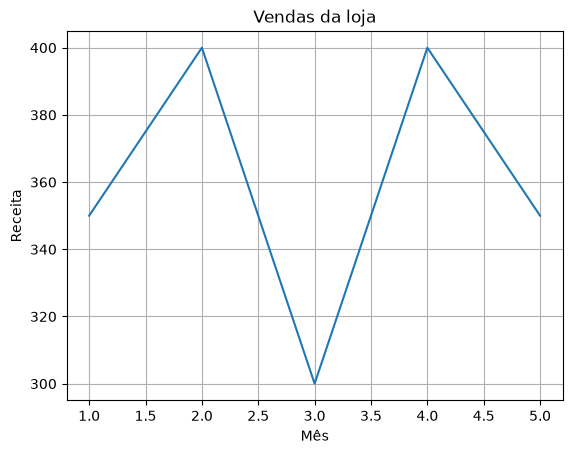

In [21]:
import matplotlib.pyplot as plt
%matplotlib inline

x = [1, 2, 3, 4, 5]                      # meses
y = [350, 400, 300, 400, 350]            # receita

plt.plot(x, y)
plt.title('Vendas da loja')
plt.xlabel('Mês')
plt.ylabel('Receita')
plt.grid(True)
# plt.savefig('Fig_1.png')               # descomente para salvar a figura em arquivo
plt.show()

### Várias linhas e legenda
Cada `plt.plot` adiciona uma linha. O `label` dá nome a ela, e `plt.legend()` mostra a legenda (use `loc='center'`, `loc='upper left'`, etc. para posicionar).

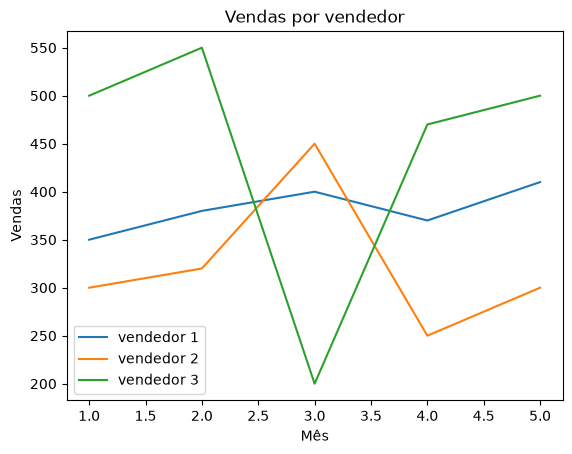

In [22]:
import matplotlib.pyplot as plt

mes = [1, 2, 3, 4, 5]
ven1 = [350, 380, 400, 370, 410]
ven2 = [300, 320, 450, 250, 300]
ven3 = [500, 550, 200, 470, 500]

plt.plot(mes, ven1, label='vendedor 1')
plt.plot(mes, ven2, label='vendedor 2')
plt.plot(mes, ven3, label='vendedor 3')
plt.title('Vendas por vendedor')
plt.xlabel('Mês')
plt.ylabel('Vendas')
plt.legend()
plt.show()

### Dispersão (`scatter`) + linha
`scatter` desenha só os pontos; `plot` liga os pontos com linhas. Dá para combinar os dois no mesmo gráfico.

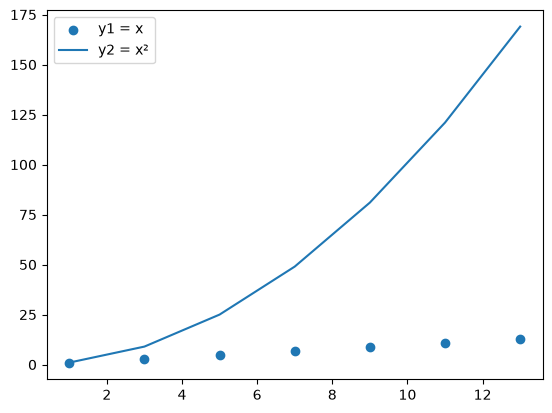

In [23]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(1, 15, 2)
y1 = x
y2 = x ** 2

plt.scatter(x, y1, label='y1 = x')
plt.plot(x, y2, label='y2 = x²')
plt.legend()
plt.show()

### Barras
`plt.bar` para barras verticais e `plt.barh` para horizontais.

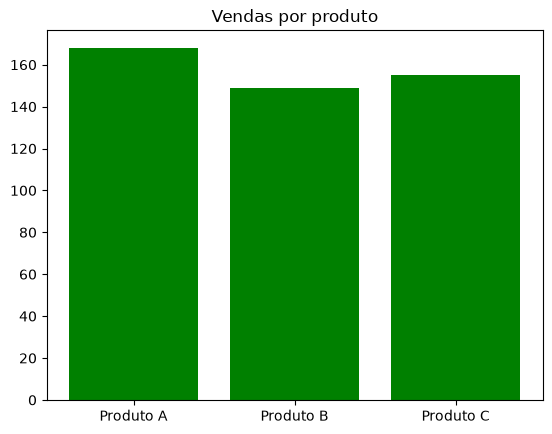

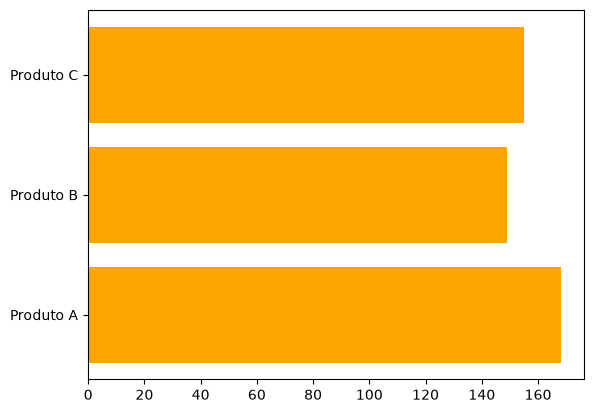

In [24]:
import matplotlib.pyplot as plt
import numpy as np

grupos = ['Produto A', 'Produto B', 'Produto C']
valores = np.random.randint(100, 300, 3)

plt.bar(grupos, valores, color='green')
plt.title('Vendas por produto')
plt.show()

plt.barh(grupos, valores, color='orange')       # horizontal
plt.show()

### Escala logarítmica
Quando os valores crescem muito rápido, `plt.yscale('log')` deixa o gráfico legível.

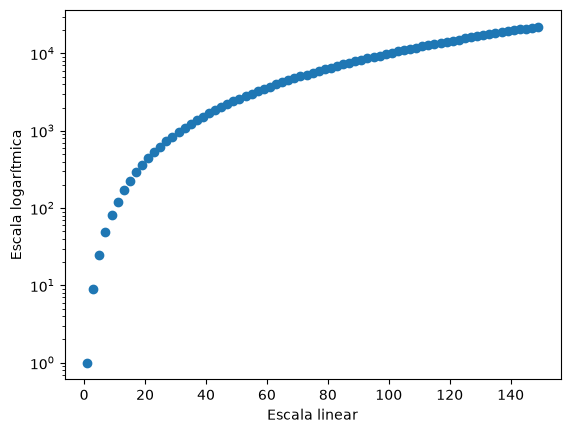

In [25]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(1, 150, 2)
y2 = x ** 2

plt.scatter(x, y2)
plt.xlabel('Escala linear')
plt.yscale('log')
plt.ylabel('Escala logarítmica')
plt.show()

### Juntando NumPy e Matplotlib
`np.linspace` gera muitos pontos para curvas suaves. Dá para colocar vários gráficos lado a lado com `plt.subplots`.

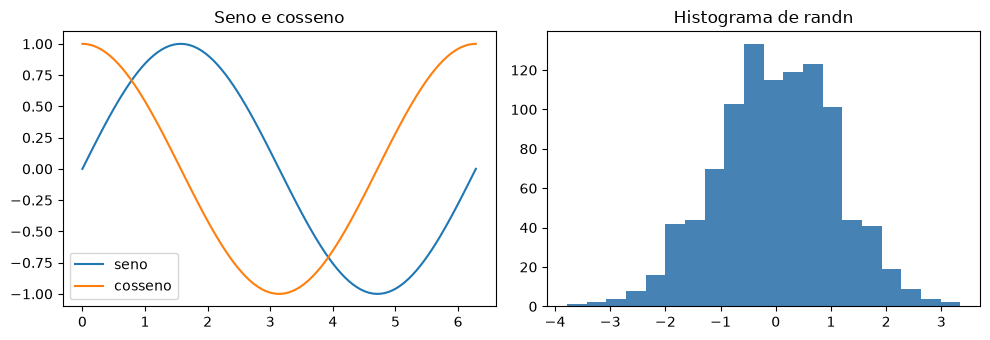

In [26]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(0, 2 * np.pi, 100)

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5))

eixos[0].plot(x, np.sin(x), label='seno')
eixos[0].plot(x, np.cos(x), label='cosseno')
eixos[0].set_title('Seno e cosseno')
eixos[0].legend()

dados = np.random.randn(1000)                    # 1000 valores de uma normal
eixos[1].hist(dados, bins=20, color='steelblue')
eixos[1].set_title('Histograma de randn')

plt.tight_layout()
plt.show()

## ✏️ Sua vez

1. Crie um vetor com os números de 1 a 20 e mostre só os **pares** (dica: máscara booleana com `%`).
2. Gere uma matriz 6×6 com `randint(1, 100)` (use `seed`) e mostre: a diagonal principal (`np.diag`), a soma de cada linha e o maior valor.
3. Faça um gráfico de linhas com as temperaturas de 7 dias de duas cidades, com título, rótulos e legenda.
4. Faça um gráfico de barras com as médias de 4 turmas e pinte de vermelho a barra da menor média.

In [27]:
# Exercício 1
import numpy as np

v = np.arange(1, 21)
pares = v[v % 2 == 0]
print(pares)

[ 2  4  6  8 10 12 14 16 18 20]


In [28]:
# Exercício 2
import numpy as np

np.random.seed(42)
m = np.random.randint(1, 101, size=(6, 6))

print('Matriz:')
print(m)
print('Diagonal principal:', np.diag(m))
print('Soma de cada linha:', m.sum(axis=1))
print('Maior valor:', m.max())

Matriz:
[[ 52  93  15  72  61  21]
 [ 83  87  75  75  88 100]
 [ 24   3  22  53   2  88]
 [ 30  38   2  64  60  21]
 [ 33  76  58  22  89  49]
 [ 91  59  42  92  60  80]]
Diagonal principal: [52 87 22 64 89 80]
Soma de cada linha: [314 508 192 215 327 424]
Maior valor: 100


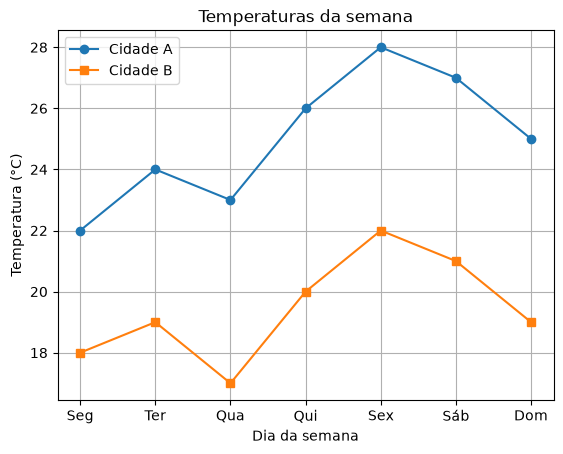

In [29]:
# Exercício 3
import matplotlib.pyplot as plt

dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
cidade_a = [22, 24, 23, 26, 28, 27, 25]
cidade_b = [18, 19, 17, 20, 22, 21, 19]

plt.plot(dias, cidade_a, marker='o', label='Cidade A')
plt.plot(dias, cidade_b, marker='s', label='Cidade B')

plt.title('Temperaturas da semana')
plt.xlabel('Dia da semana')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.grid(True)
plt.show()

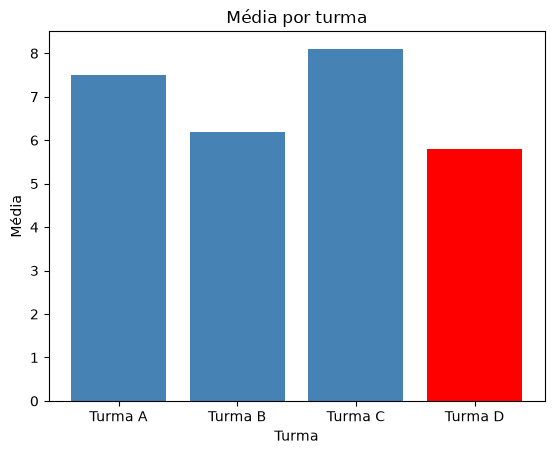

In [30]:
# Exercício 4
import matplotlib.pyplot as plt

turmas = ['Turma A', 'Turma B', 'Turma C', 'Turma D']
medias = [7.5, 6.2, 8.1, 5.8]

cores = []
for m in medias:
    if m == min(medias):
        cores.append('red')
    else:
        cores.append('steelblue')

plt.bar(turmas, medias, color=cores)

plt.title('Média por turma')
plt.xlabel('Turma')
plt.ylabel('Média')
plt.show()

## Aprofundamento 1 — Gerador moderno do NumPy
`np.random.default_rng()` cria um gerador local, evita depender do estado aleatório global e permite reproduzir exemplos com uma semente.

In [31]:
import numpy as np
rng_a = np.random.default_rng(42)
rng_b = np.random.default_rng(42)
a = rng_a.integers(0, 10, size=(3, 4))
b = rng_b.integers(0, 10, size=(3, 4))
assert np.array_equal(a, b)
print("Matriz reproduzível:\n", a)

Matriz reproduzível:
 [[0 7 6 4]
 [4 8 0 6]
 [2 0 5 9]]


## Aprofundamento 2 — Broadcasting e eixos
`axis=0` agrega ao longo das linhas (por coluna); `axis=1`, ao longo das colunas (por linha). Em broadcasting, as dimensões devem coincidir ou uma delas deve valer 1.

In [32]:
notas = np.array([[7., 8., 9.], [6., 7., 8.]])
medias_alunos = notas.mean(axis=1)
medias_provas = notas.mean(axis=0)
notas_bonus = notas + np.array([0., 0.5, 1.])
assert medias_alunos.shape == (2,)
assert medias_provas.shape == (3,)
assert notas_bonus.shape == notas.shape
print("Médias por aluno:", medias_alunos)

Médias por aluno: [8. 7.]


## Aprofundamento 3 — Gráficos reproduzíveis e legíveis
Use a API orientada a objetos (`fig, ax`), identifique eixos, inclua unidade e feche as figuras quando necessário. Não há obrigação de salvar o arquivo para aprender a construir o gráfico.

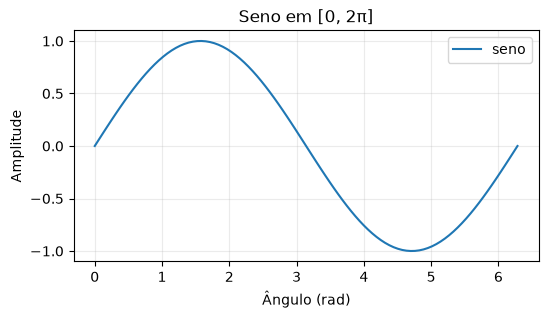

In [33]:
import matplotlib.pyplot as plt
x = np.linspace(0, 2*np.pi, 100)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, np.sin(x), label="seno")
ax.set(xlabel="Ângulo (rad)", ylabel="Amplitude", title="Seno em [0, 2π]")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

### Exercício com solução
Calcule a proporção de valores positivos por linha de uma matriz e confirme que o resultado fica entre 0 e 1.

In [34]:
valores = np.array([[-1, 3, 2], [0, -2, -3], [1, 1, 1]])
fracoes = (valores > 0).mean(axis=1)
assert np.all((fracoes >= 0) & (fracoes <= 1))
print("Proporção positiva por linha:", fracoes)

Proporção positiva por linha: [0.66666667 0.         1.        ]
